Original dataset shape: (8807, 12)

First five rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing values before cleaning:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration

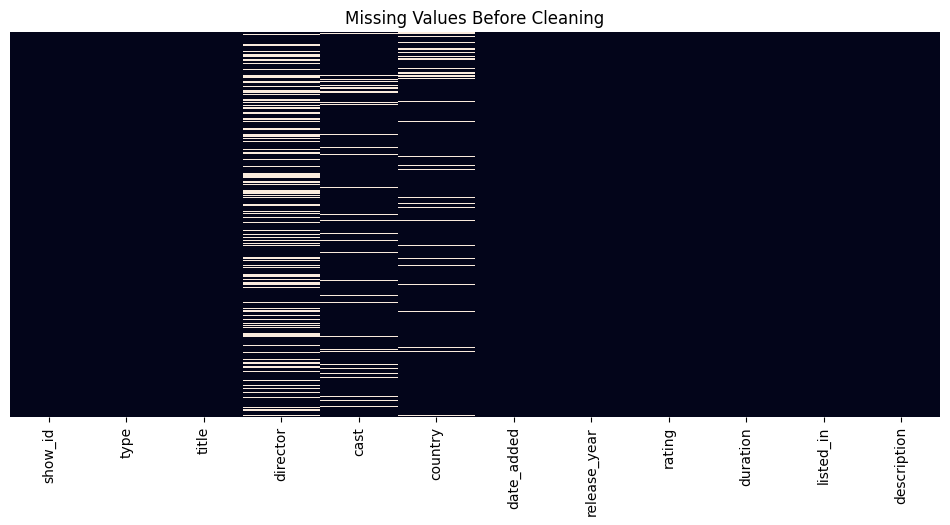

Duplicate rows: 0

Missing values after cleaning:
show_id             0
type                0
title               0
director            0
cast                0
country             0
date_added         98
release_year        0
rating              0
duration            0
listed_in           0
description         0
date_added_year    98
dtype: int64

Duplicate rows after cleaning: 0

Cleaned dataset shape: (8807, 13)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,date_added_year
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,Pg-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021
1,s2,Tv Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Tv-Ma,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021
2,s3,Tv Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,Tv-Ma,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021
3,s4,Tv Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,Tv-Ma,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021
4,s5,Tv Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,Tv-Ma,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021



Cleaned dataset saved successfully!


In [2]:
# Task 1: Netflix Data Cleaning and Preprocessing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

# Step 1: Load the dataset (Extract if necessary)
zip_path = "/content/netflix_titles.csv.zip"
extract_path = "/content/"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

df = pd.read_csv("/content/netflix_titles.csv")
print("Original dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

# Step 2: Check dataset information
print("\nDataset information:")
df.info()

# Step 3: Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Before Cleaning")
plt.show()

# Step 4: Remove duplicate records
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Step 5: Handle missing values
# Fill missing text fields with 'Unknown'
text_columns = ["director", "cast", "country", "rating",
                 "duration", "listed_in", "description"]
for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

# Step 6: Convert date_added into a proper date format
df["date_added"] = pd.to_datetime(
    df["date_added"], errors="coerce"
)

# Step 7: Clean categorical columns
for col in ["type", "rating"]:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# Step 8: Convert release_year to numeric
df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
).astype("Int64")

# Step 9: Create a new feature for content addition year
df["date_added_year"] = df["date_added"].dt.year.astype("Int64")

# Step 10: Check the cleaned dataset
print("\nMissing values after cleaning:")
print(df.isnull().sum())
print("\nDuplicate rows after cleaning:", df.duplicated().sum())
print("\nCleaned dataset shape:", df.shape)

display(df.head())

# Step 11: Save the cleaned dataset
df.to_csv("/content/netflix_titles_cleaned.csv", index=False)
print("\nCleaned dataset saved successfully!")

In [1]:
from google.colab import files
files.download("/content/netflix_titles_cleaned.csv")

FileNotFoundError: Cannot find file: /content/netflix_titles_cleaned.csv